In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import resnet50

warnings.filterwarnings("ignore")

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Device: cpu
Running on CPU


In [3]:
test_df = pd.read_csv("test/_classes.csv")

test_df["split"] = "test"

label_columns = test_df.columns[1:-1]

test_df["label"] = test_df[label_columns].idxmax(axis=1)

print("Number of test images:", len(test_df))
print("Number of classes:", len(label_columns))

test_df.head()

Number of test images: 176
Number of classes: 16


,filename,anold-chiari-malformation,arachnoid-cyst,cerebellah-hypoplasia,colphocephaly,encephalocele,holoprosencephaly,hydracenphaly,intracranial-hemorrdge,intracranial-tumor,m-magna,mild-ventriculomegaly,moderate-ventriculomegaly,normal,polencephaly,severe-ventriculomegaly,vein-of-galen,split,label
0,Copy-of-mild-ventriculomegaly-18c_aug_2_png_jp...,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,test,mild-ventriculomegaly
1,Copy-of-intracranial-hemorrdge-34a_aug_4_png_j...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,test,intracranial-hemorrdge
2,Copy-of-moderate-ventriculomegaly-34_aug_4_png...,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,test,moderate-ventriculomegaly
3,Copy-of-polencephaly30k_aug_2_png_jpg.rf.05b0e...,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,test,polencephaly
4,Copy-of-encephalocele-4-32c_aug_4_png_jpg.rf.0...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,test,encephalocele


In [4]:
with open("class_mapping.json", "r") as f:
    class_to_idx = json.load(f)

idx_to_class = {
    int(index): class_name
    for class_name, index in class_to_idx.items()
}

classes = [idx_to_class[i] for i in range(len(idx_to_class))]

print("Classes:")
for i, cls in enumerate(classes):
    print(i, ":", cls)

Classes:
0 :  anold-chiari-malformation
1 :  arachnoid-cyst
2 :  cerebellah-hypoplasia
3 :  colphocephaly
4 :  encephalocele
5 :  holoprosencephaly
6 :  hydracenphaly
7 :  intracranial-hemorrdge
8 :  intracranial-tumor
9 :  m-magna
10 :  mild-ventriculomegaly
11 :  moderate-ventriculomegaly
12 :  normal
13 :  polencephaly
14 :  severe-ventriculomegaly
15 :  vein-of-galen


In [5]:
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [6]:
class FetalTestDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = os.path.join(
            row["split"],
            row["filename"]
        )

        image = Image.open(image_path).convert("RGB")

        original_image = image.copy()

        if self.transform:
            image = self.transform(image)

        label = row["label"]

        return image, label, original_image, row["filename"]

In [7]:
test_dataset = FetalTestDataset(
    test_df,
    transform=test_transform
)

print("Test dataset size:", len(test_dataset))

Test dataset size: 176


In [8]:
num_classes = len(classes)

model = resnet50(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

model.load_state_dict(
    torch.load(
        "best_resnet50.pth",
        map_location=device
    )
)

model.eval()

print("ResNet50 model loaded successfully.")

ResNet50 model loaded successfully.


In [9]:
target_layer = model.layer4[-1].conv3

print(target_layer)

Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [10]:
activations = None
gradients = None

In [11]:
def forward_hook(module, input, output):
    global activations
    activations = output

In [12]:
def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

In [13]:
forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

print("Grad-CAM hooks registered.")

Grad-CAM hooks registered.


In [14]:
def generate_gradcam(model, image_tensor, target_class):

    global activations
    global gradients

    model.zero_grad()

    output = model(image_tensor)

    target_score = output[:, target_class]

    target_score.backward()

    activation = activations.detach()
    gradient = gradients.detach()

    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (weights * activation).sum(
        dim=1,
        keepdim=True
    )

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze()

    cam -= cam.min()

    if cam.max() != 0:
        cam /= cam.max()

    return cam.cpu().numpy(), output

In [15]:
image_index = 0

image_tensor, true_label, original_image, filename = test_dataset[image_index]

print("Filename:", filename)
print("True class:", true_label)

Filename: Copy-of-mild-ventriculomegaly-18c_aug_2_png_jpg.rf.1a7978b80bec239d05c1870f509b7aaa.jpg
True class:  mild-ventriculomegaly


In [16]:
input_tensor = image_tensor.unsqueeze(0).to(device)

print("Input shape:", input_tensor.shape)

Input shape: torch.Size([1, 3, 224, 224])


In [17]:
with torch.no_grad():
    output = model(input_tensor)

probabilities = torch.softmax(output, dim=1)

predicted_class = torch.argmax(
    probabilities,
    dim=1
).item()

confidence = probabilities[0, predicted_class].item()

predicted_label = idx_to_class[predicted_class]

print("True class:", true_label)
print("Predicted class:", predicted_label)
print("Confidence:", f"{confidence * 100:.2f}%")

True class:  mild-ventriculomegaly
Predicted class:  mild-ventriculomegaly
Confidence: 54.69%


In [18]:
cam, output = generate_gradcam(
    model,
    input_tensor,
    predicted_class
)

print("Grad-CAM generated.")
print("CAM shape:", cam.shape)

Grad-CAM generated.
CAM shape: (224, 224)


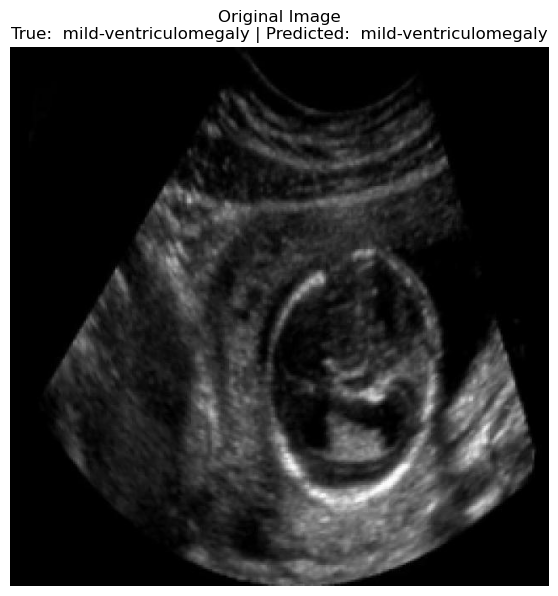

In [19]:
plt.figure(figsize=(7, 7))

plt.imshow(original_image)

plt.title(
    f"Original Image\n"
    f"True: {true_label} | Predicted: {predicted_label}"
)

plt.axis("off")
plt.show()

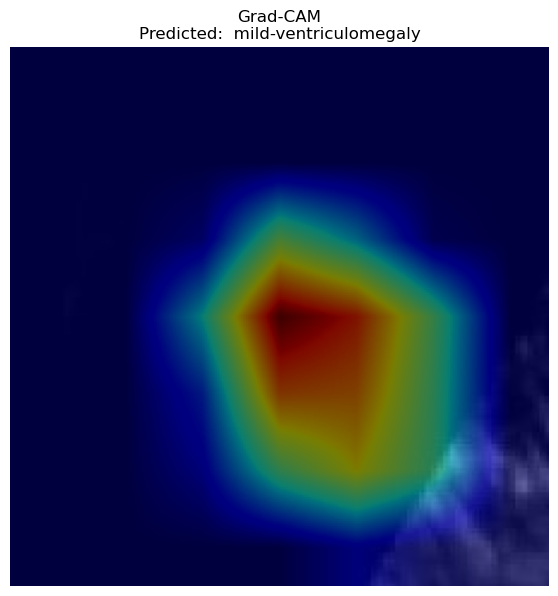

In [20]:
plt.figure(figsize=(7, 7))

plt.imshow(original_image)
plt.imshow(
    cam,
    cmap="jet",
    alpha=0.5
)

plt.title(
    f"Grad-CAM\n"
    f"Predicted: {predicted_label}"
)

plt.axis("off")
plt.show()

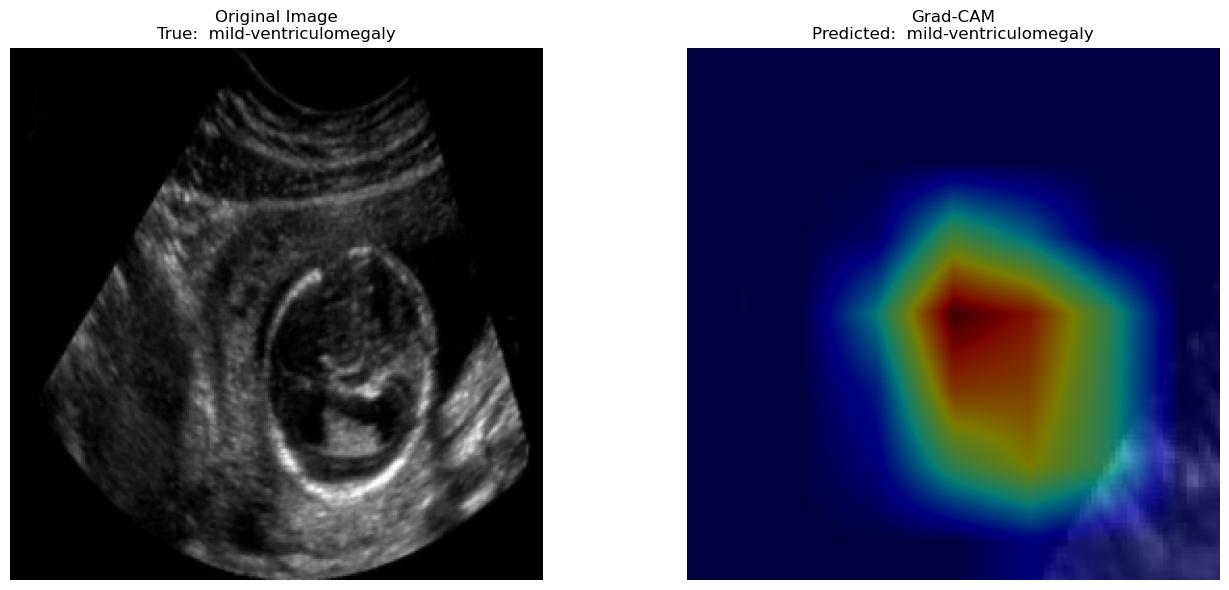

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original_image)
axes[0].set_title(
    f"Original Image\nTrue: {true_label}"
)
axes[0].axis("off")

axes[1].imshow(original_image)
axes[1].imshow(
    cam,
    cmap="jet",
    alpha=0.5
)
axes[1].set_title(
    f"Grad-CAM\nPredicted: {predicted_label}"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [22]:
probabilities_np = probabilities.squeeze().cpu().numpy()

probability_df = pd.DataFrame({
    "Class": classes,
    "Probability": probabilities_np
})

probability_df = probability_df.sort_values(
    "Probability",
    ascending=False
)

probability_df

,Class,Probability
10,mild-ventriculomegaly,0.546881
13,polencephaly,0.219248
2,cerebellah-hypoplasia,0.045986
11,moderate-ventriculomegaly,0.037999
14,severe-ventriculomegaly,0.035448
6,hydracenphaly,0.032015
7,intracranial-hemorrdge,0.031575
4,encephalocele,0.010640
15,vein-of-galen,0.009372
3,colphocephaly,0.008602


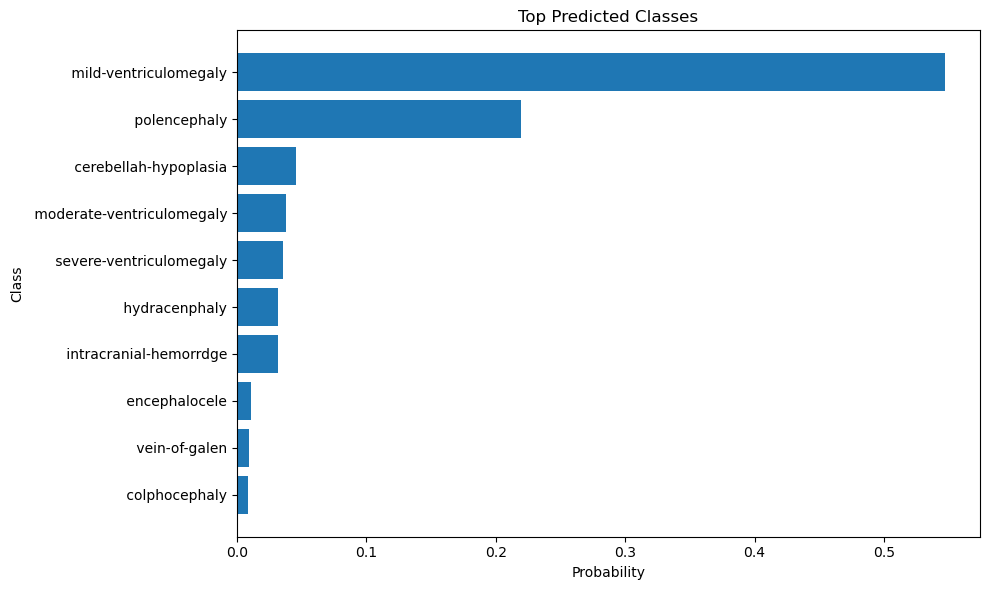

In [23]:
top_n = min(10, len(probability_df))

plot_df = probability_df.head(top_n)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Class"][::-1],
    plot_df["Probability"][::-1]
)

plt.xlabel("Probability")
plt.ylabel("Class")
plt.title("Top Predicted Classes")

plt.tight_layout()
plt.show()

In [25]:
def show_gradcam(
    dataset,
    image_index,
    model,
    idx_to_class
):

    image_tensor, true_label, original_image, filename = dataset[image_index]

    input_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)

    probabilities = torch.softmax(output, dim=1)

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

    confidence = probabilities[
        0,
        predicted_class
    ].item()

    predicted_label = idx_to_class[predicted_class]

    cam, _ = generate_gradcam(
        model,
        input_tensor,
        predicted_class
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6)
    )

    axes[0].imshow(original_image)
    axes[0].set_title(
        f"Original\nTrue: {true_label}"
    )
    axes[0].axis("off")

    axes[1].imshow(cam, cmap="jet")
    axes[1].set_title(
        f"Grad-CAM\n{predicted_label}"
    )
    axes[1].axis("off")

    axes[2].imshow(original_image)
    axes[2].imshow(
        cam,
        cmap="jet",
        alpha=0.5
    )
    axes[2].set_title(
        f"Overlay\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    print("Filename:", filename)
    print("True class:", true_label)
    print("Predicted class:", predicted_label)
    print("Confidence:", f"{confidence * 100:.2f}%")

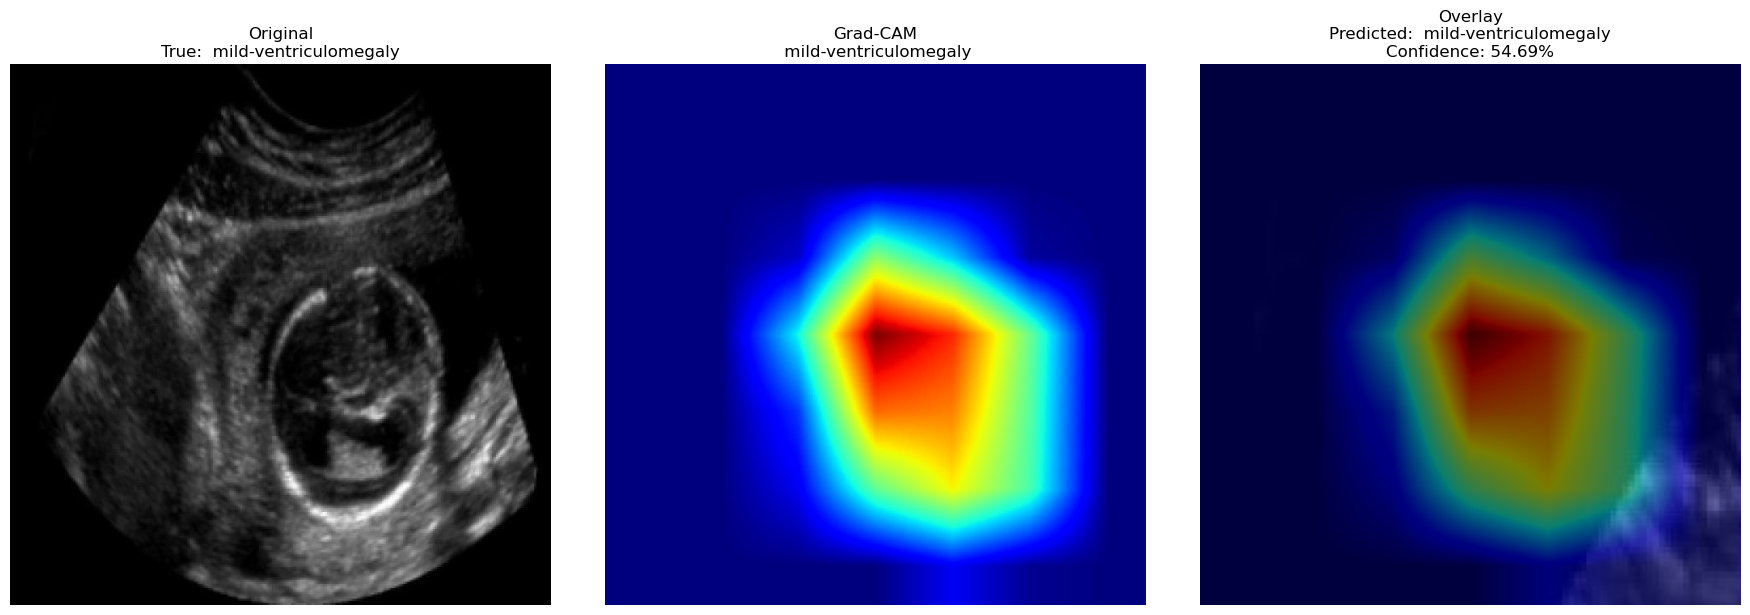

Filename: Copy-of-mild-ventriculomegaly-18c_aug_2_png_jpg.rf.1a7978b80bec239d05c1870f509b7aaa.jpg
True class:  mild-ventriculomegaly
Predicted class:  mild-ventriculomegaly
Confidence: 54.69%


In [26]:
show_gradcam(
    test_dataset,
    image_index=0,
    model=model,
    idx_to_class=idx_to_class
)


Image index: 0


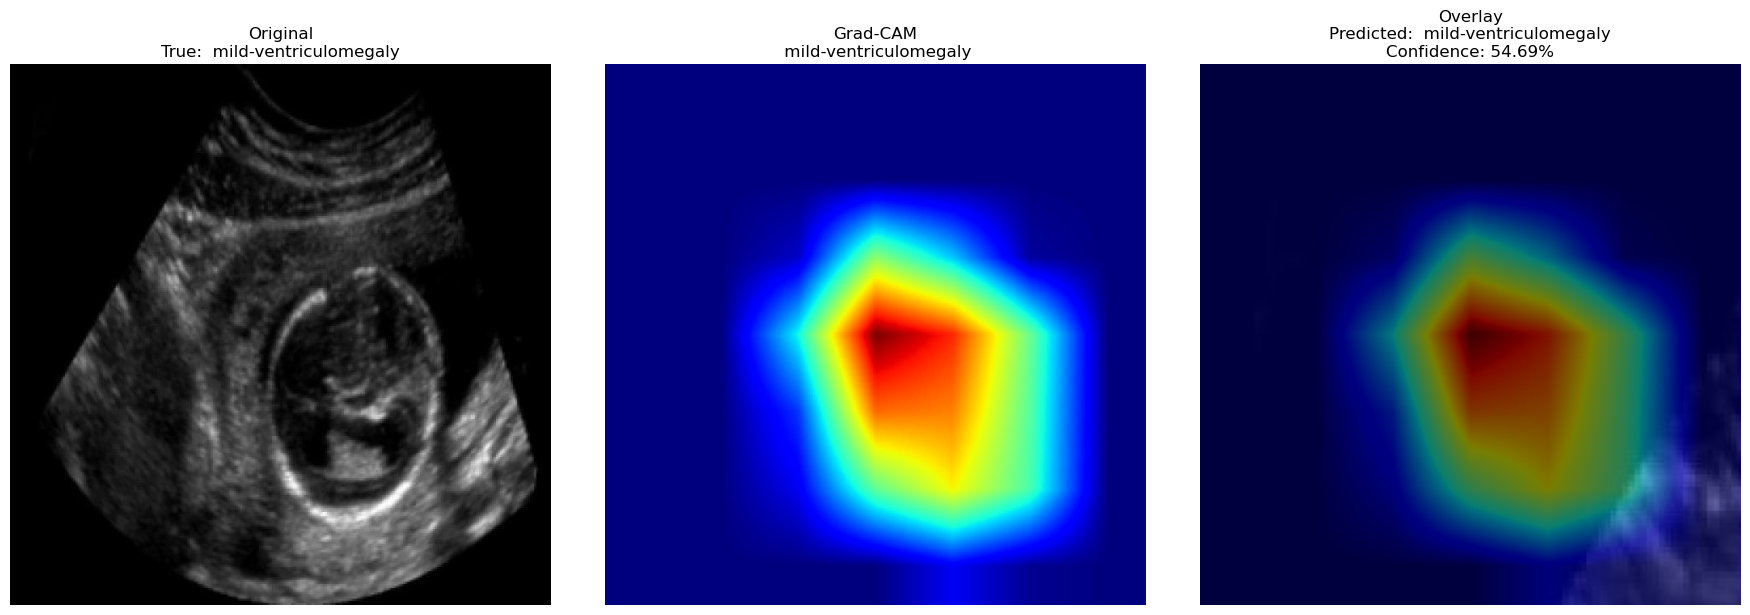

Filename: Copy-of-mild-ventriculomegaly-18c_aug_2_png_jpg.rf.1a7978b80bec239d05c1870f509b7aaa.jpg
True class:  mild-ventriculomegaly
Predicted class:  mild-ventriculomegaly
Confidence: 54.69%

Image index: 5


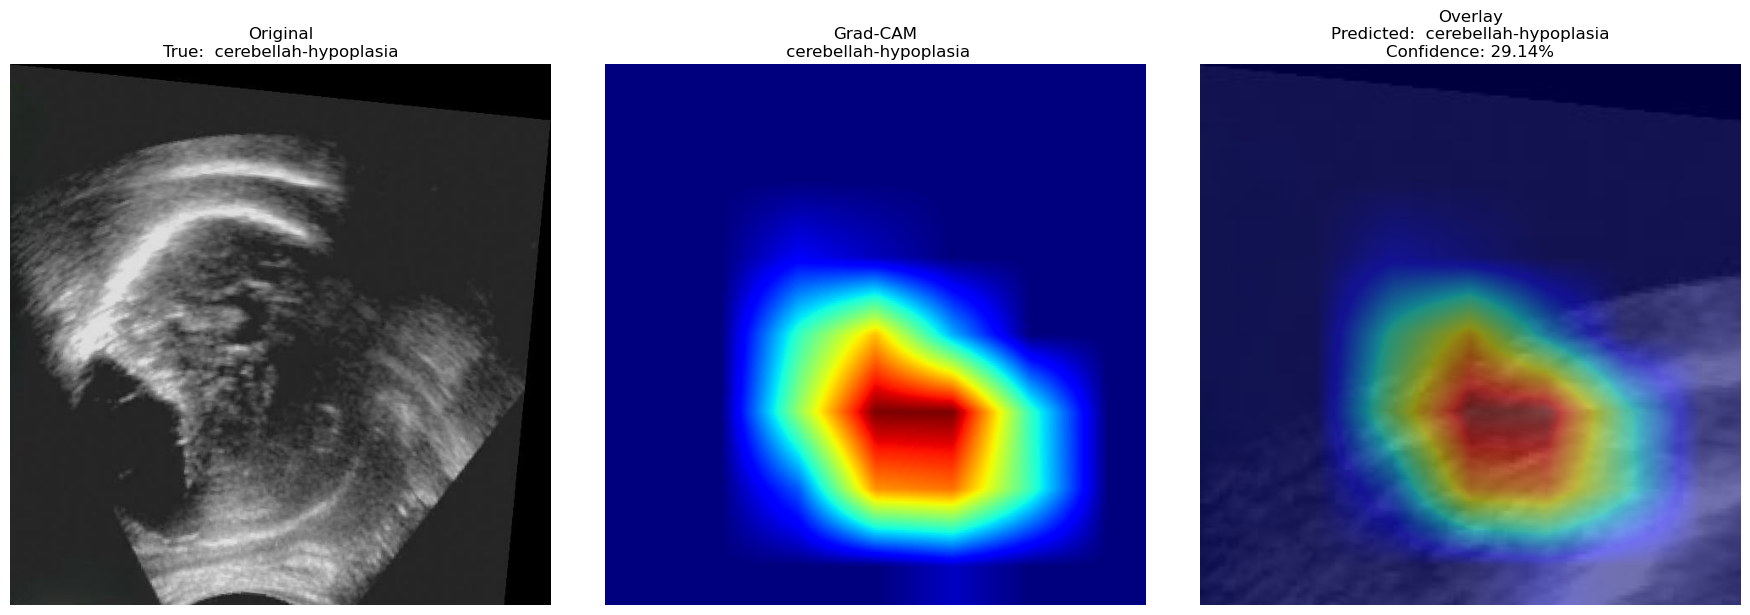

Filename: Copy-of-cerebellah-hypoplasia-36o_aug_5_png_jpg.rf.1e2abbd42aa224b867f842dce740ee3b.jpg
True class:  cerebellah-hypoplasia
Predicted class:  cerebellah-hypoplasia
Confidence: 29.14%

Image index: 10


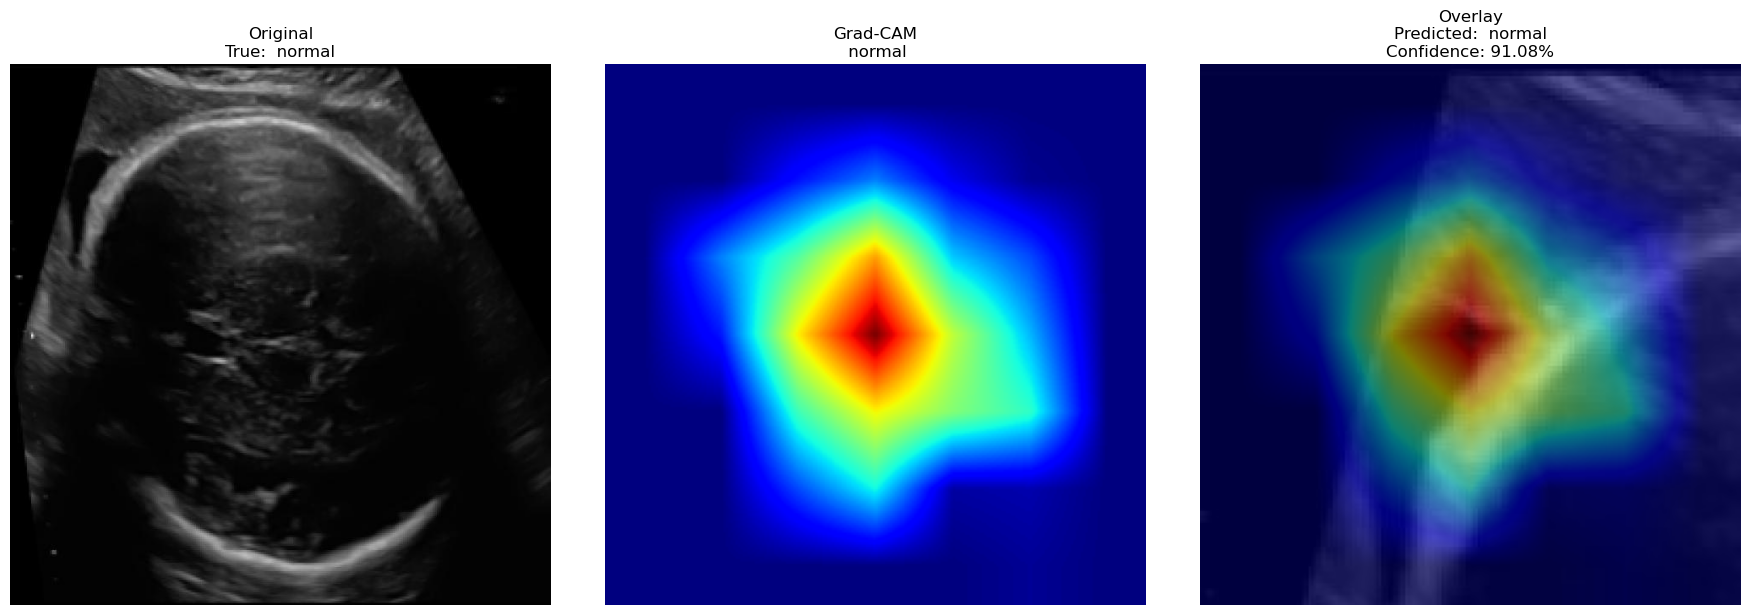

Filename: Patient00709_Plane3_1_of_3_aug_3_png_jpg.rf.1117a9081fbf9766dee6caad5459418c.jpg
True class:  normal
Predicted class:  normal
Confidence: 91.08%

Image index: 15


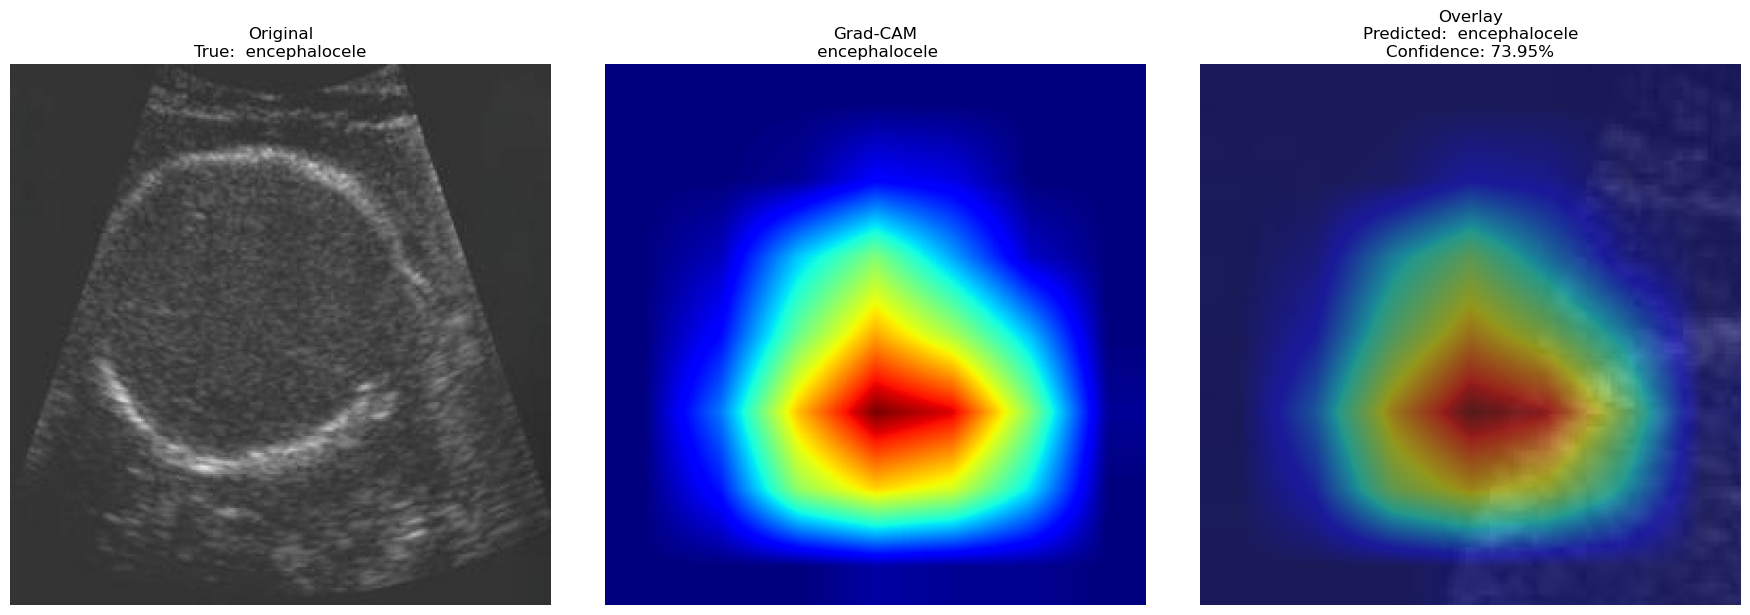

Filename: Copy-of-encephalocele1-23a_png_jpg.rf.13c875bdb4a8040639f40fdf598b45ba.jpg
True class:  encephalocele
Predicted class:  encephalocele
Confidence: 73.95%

Image index: 20


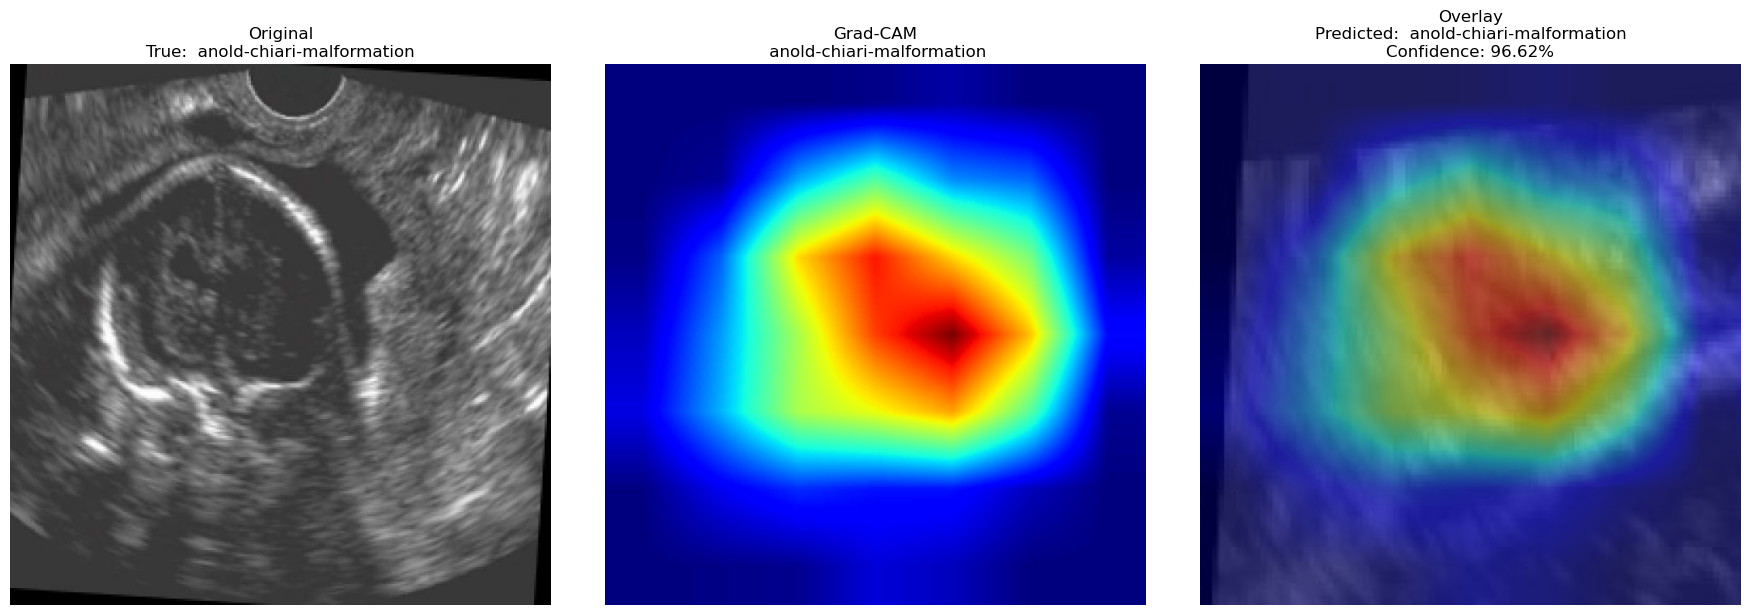

Filename: Copy-of-anold-chiari-malformation-26b_aug_2_png_jpg.rf.25de018d6b186681e0643aea0ec8511f.jpg
True class:  anold-chiari-malformation
Predicted class:  anold-chiari-malformation
Confidence: 96.62%


In [27]:
sample_indices = [0, 5, 10, 15, 20]

for index in sample_indices:

    print("\n" + "=" * 60)
    print("Image index:", index)

    show_gradcam(
        test_dataset,
        image_index=index,
        model=model,
        idx_to_class=idx_to_class
    )

In [29]:
all_predictions = []
all_true_labels = []

model.eval()

for index in range(len(test_dataset)):

    image_tensor, true_label, _, _ = test_dataset[index]

    input_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)

    predicted_class = torch.argmax(
        output,
        dim=1
    ).item()

    all_predictions.append(
        idx_to_class[predicted_class]
    )

    all_true_labels.append(true_label)

In [30]:
correct_indices = []
incorrect_indices = []

for i in range(len(test_dataset)):

    if all_predictions[i] == all_true_labels[i]:
        correct_indices.append(i)
    else:
        incorrect_indices.append(i)

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))

Correct predictions: 146
Incorrect predictions: 30


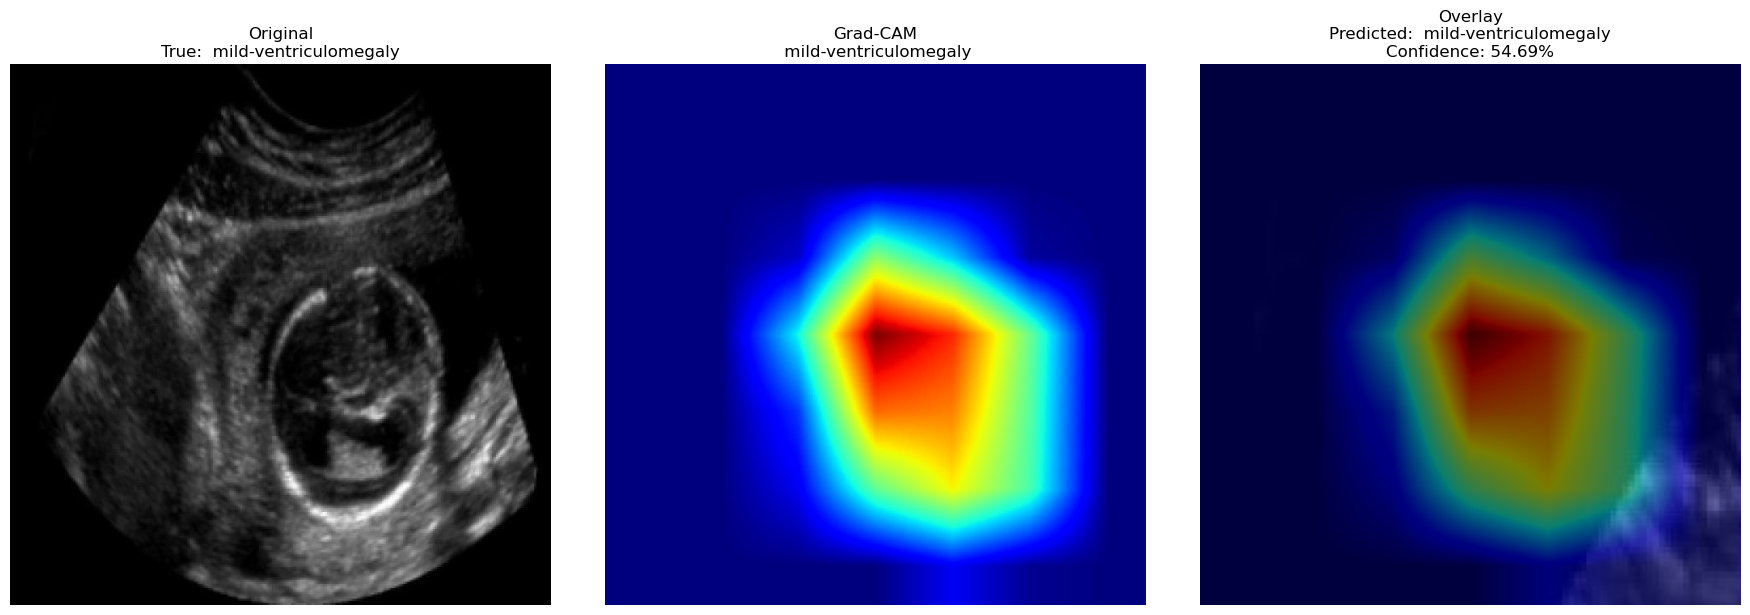

Filename: Copy-of-mild-ventriculomegaly-18c_aug_2_png_jpg.rf.1a7978b80bec239d05c1870f509b7aaa.jpg
True class:  mild-ventriculomegaly
Predicted class:  mild-ventriculomegaly
Confidence: 54.69%


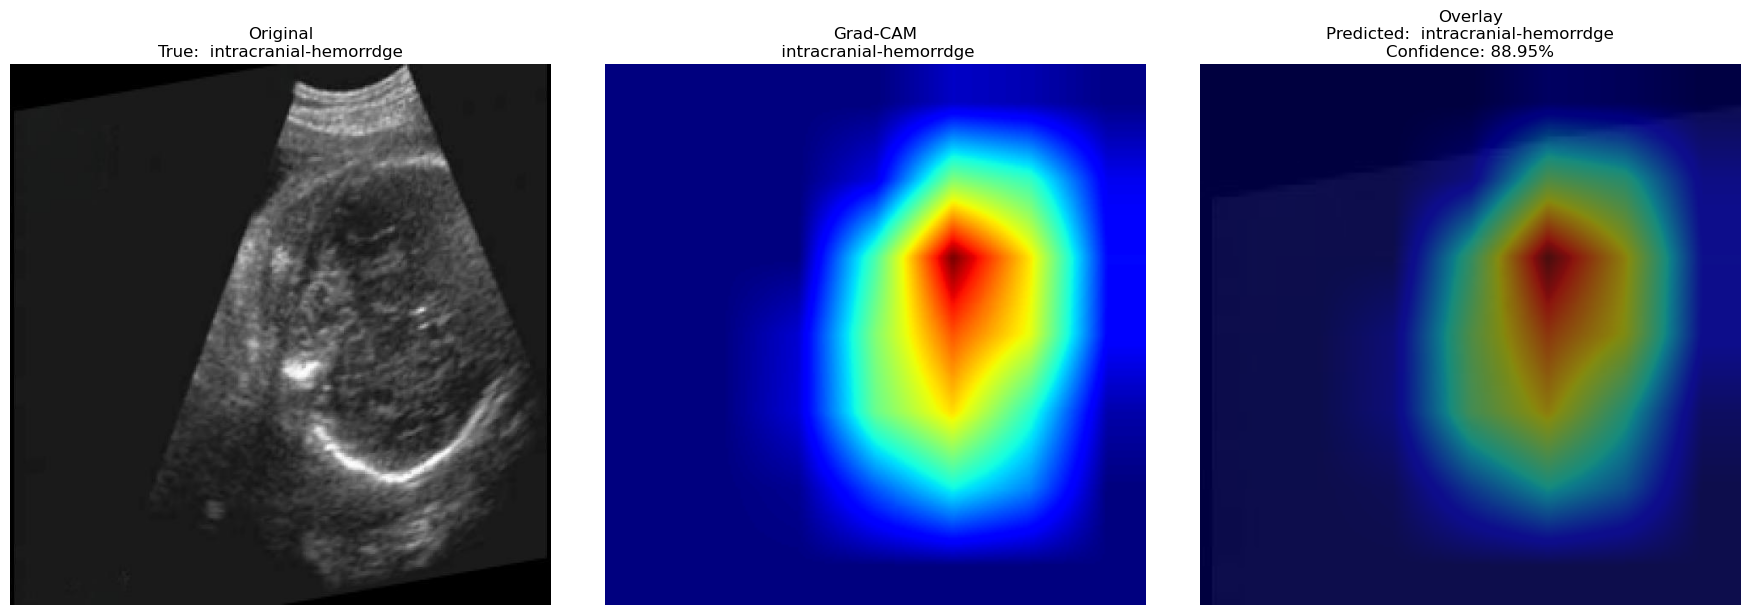

Filename: Copy-of-intracranial-hemorrdge-34a_aug_4_png_jpg.rf.28478dd858a77613009654fc5c607fe6.jpg
True class:  intracranial-hemorrdge
Predicted class:  intracranial-hemorrdge
Confidence: 88.95%


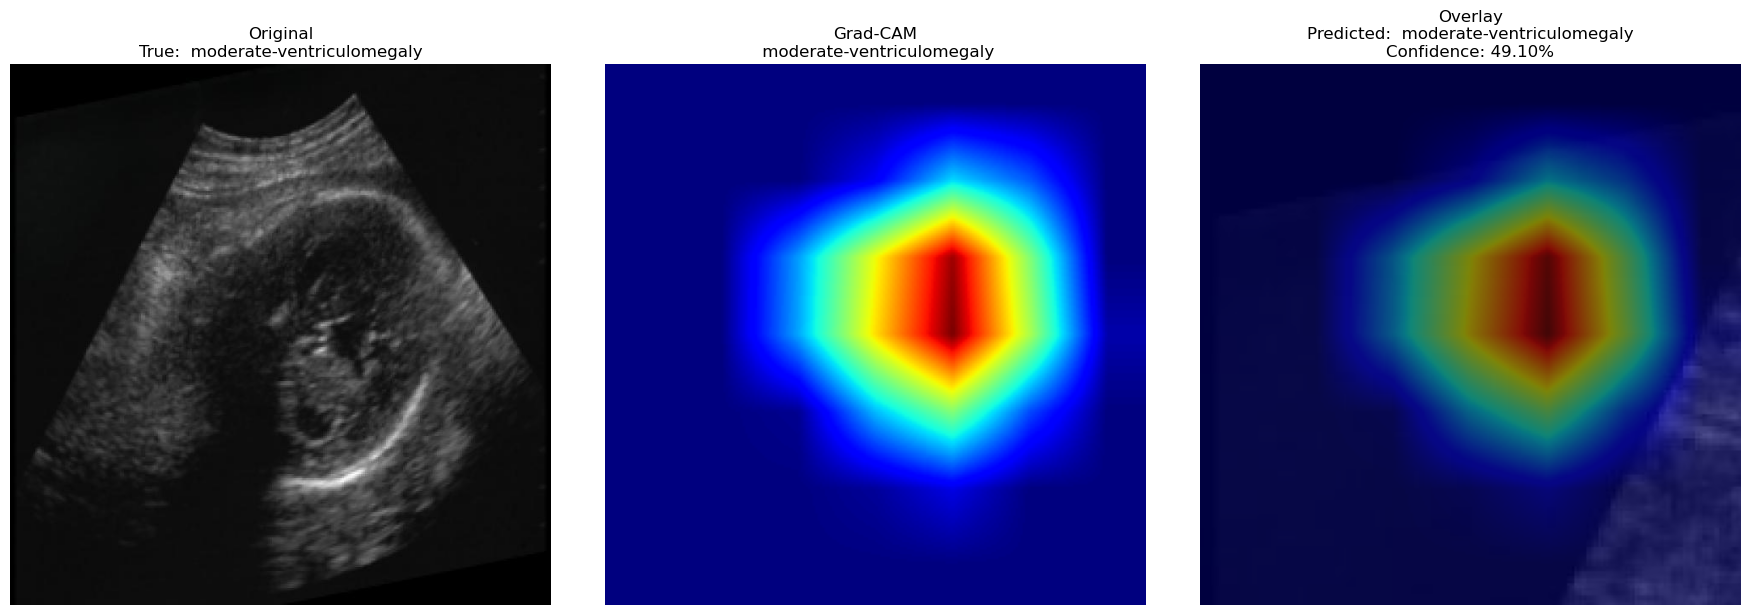

Filename: Copy-of-moderate-ventriculomegaly-34_aug_4_png_jpg.rf.041ac0a7f86dd07a611f3b55690bda4e.jpg
True class:  moderate-ventriculomegaly
Predicted class:  moderate-ventriculomegaly
Confidence: 49.10%


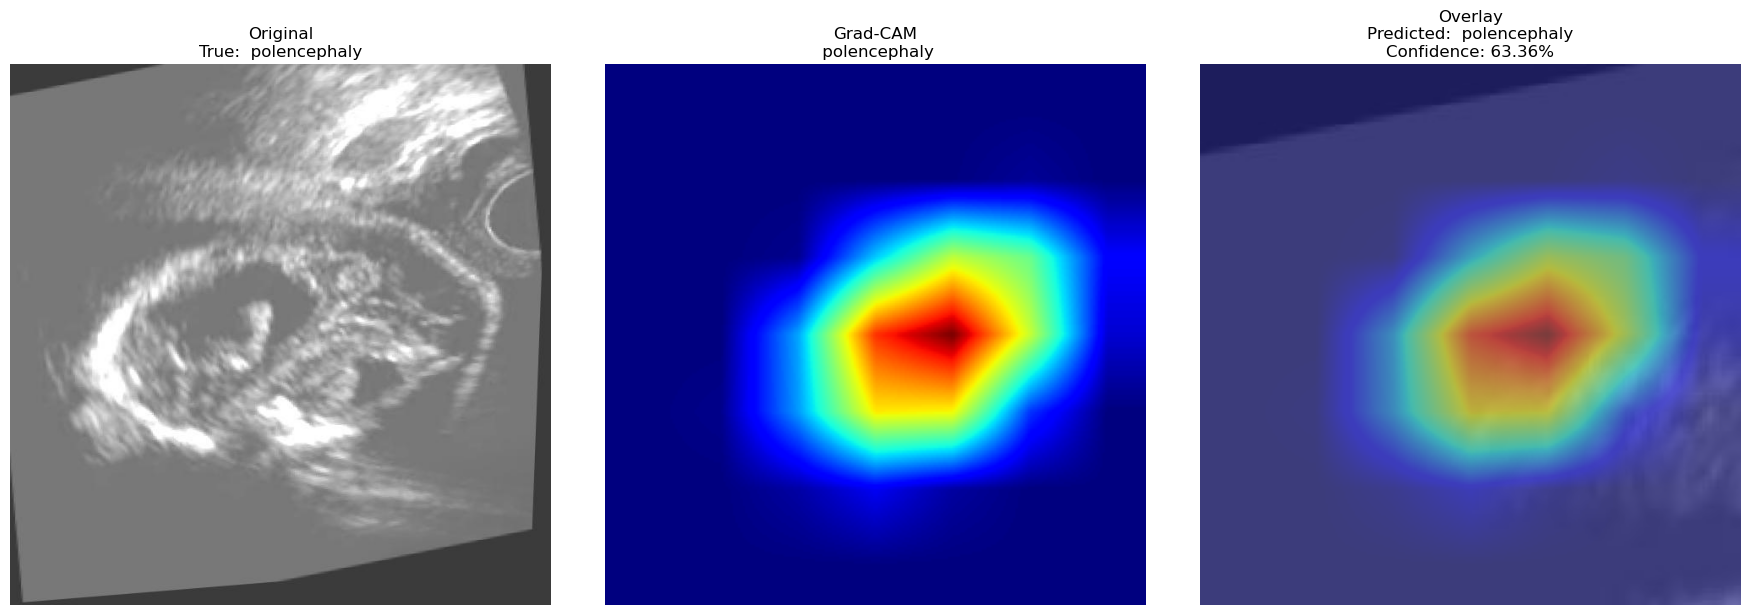

Filename: Copy-of-polencephaly30k_aug_2_png_jpg.rf.05b0e6072e5bdac34d60662b66121bfa.jpg
True class:  polencephaly
Predicted class:  polencephaly
Confidence: 63.36%


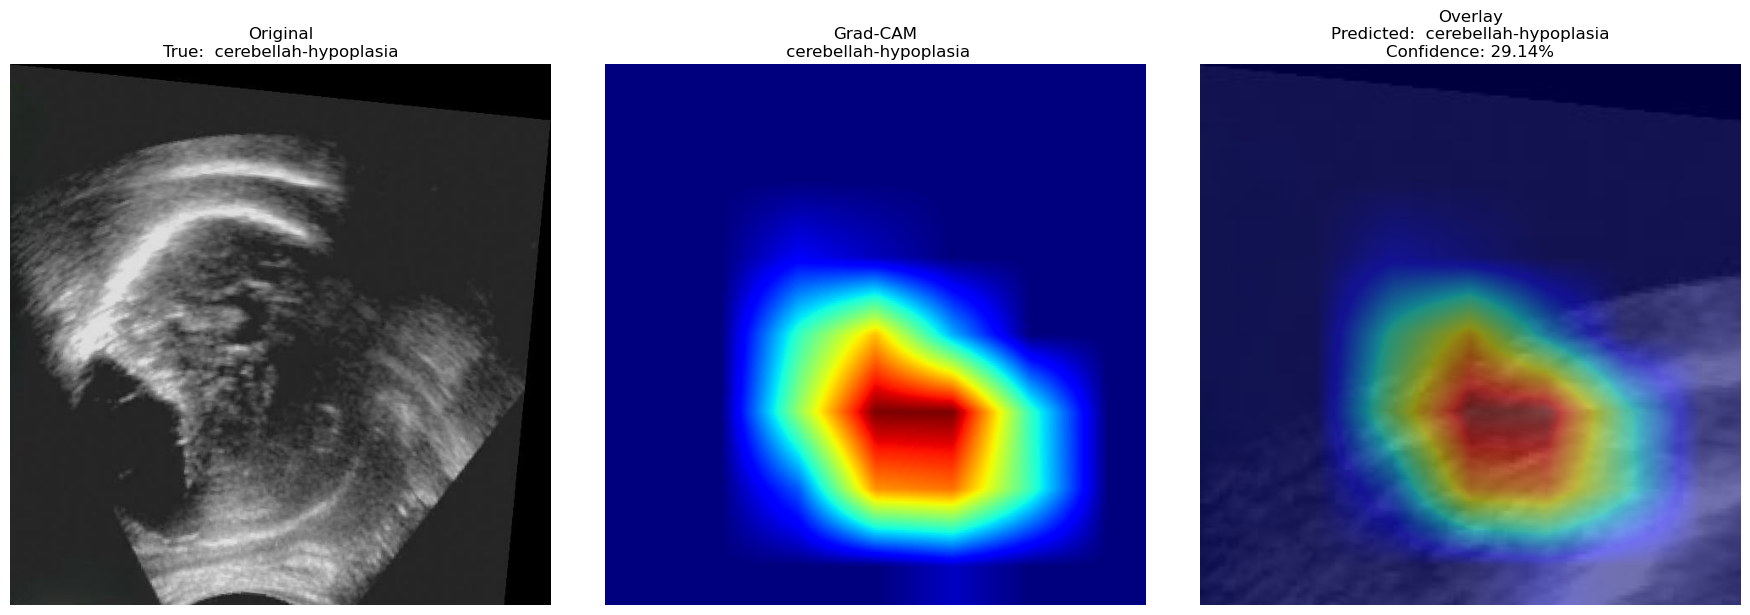

Filename: Copy-of-cerebellah-hypoplasia-36o_aug_5_png_jpg.rf.1e2abbd42aa224b867f842dce740ee3b.jpg
True class:  cerebellah-hypoplasia
Predicted class:  cerebellah-hypoplasia
Confidence: 29.14%


In [31]:
num_samples = min(5, len(correct_indices))

for index in correct_indices[:num_samples]:

    show_gradcam(
        test_dataset,
        image_index=index,
        model=model,
        idx_to_class=idx_to_class
    )

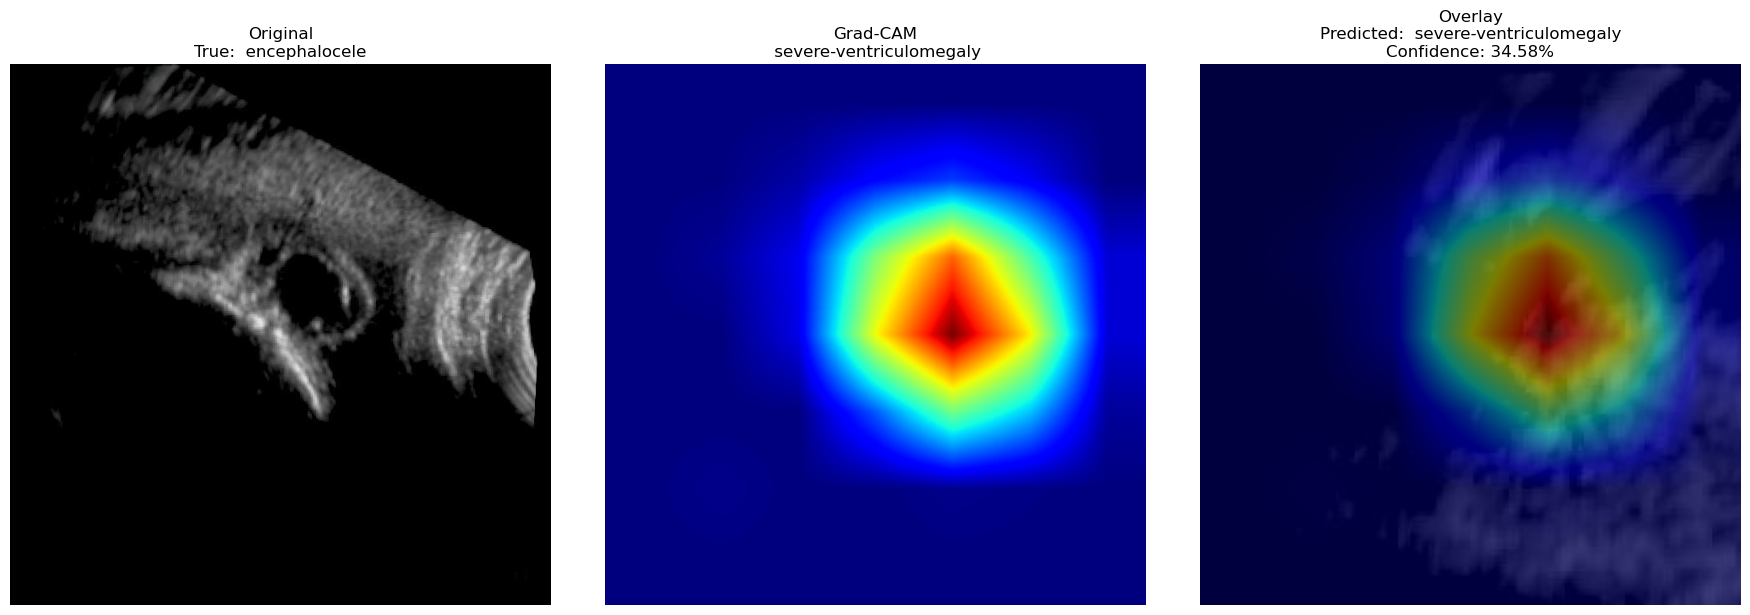

Filename: Copy-of-encephalocele-4-32c_aug_4_png_jpg.rf.0ec6707b30440bc18bfe013d30c5acdc.jpg
True class:  encephalocele
Predicted class:  severe-ventriculomegaly
Confidence: 34.58%


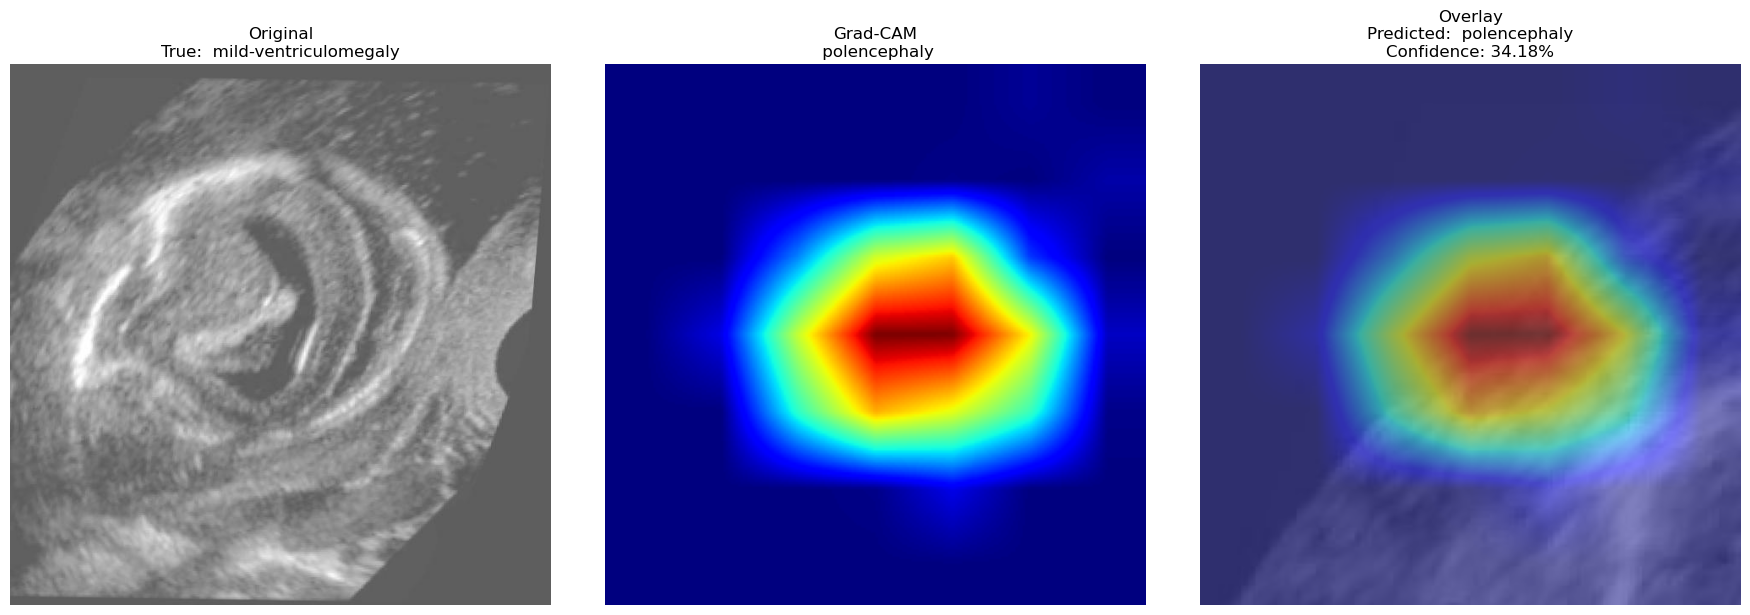

Filename: Copy-of-mild-ventriculomegaly-20a_aug_4_png_jpg.rf.233a53eff4cbc2ce3cf7042056b03e21.jpg
True class:  mild-ventriculomegaly
Predicted class:  polencephaly
Confidence: 34.18%


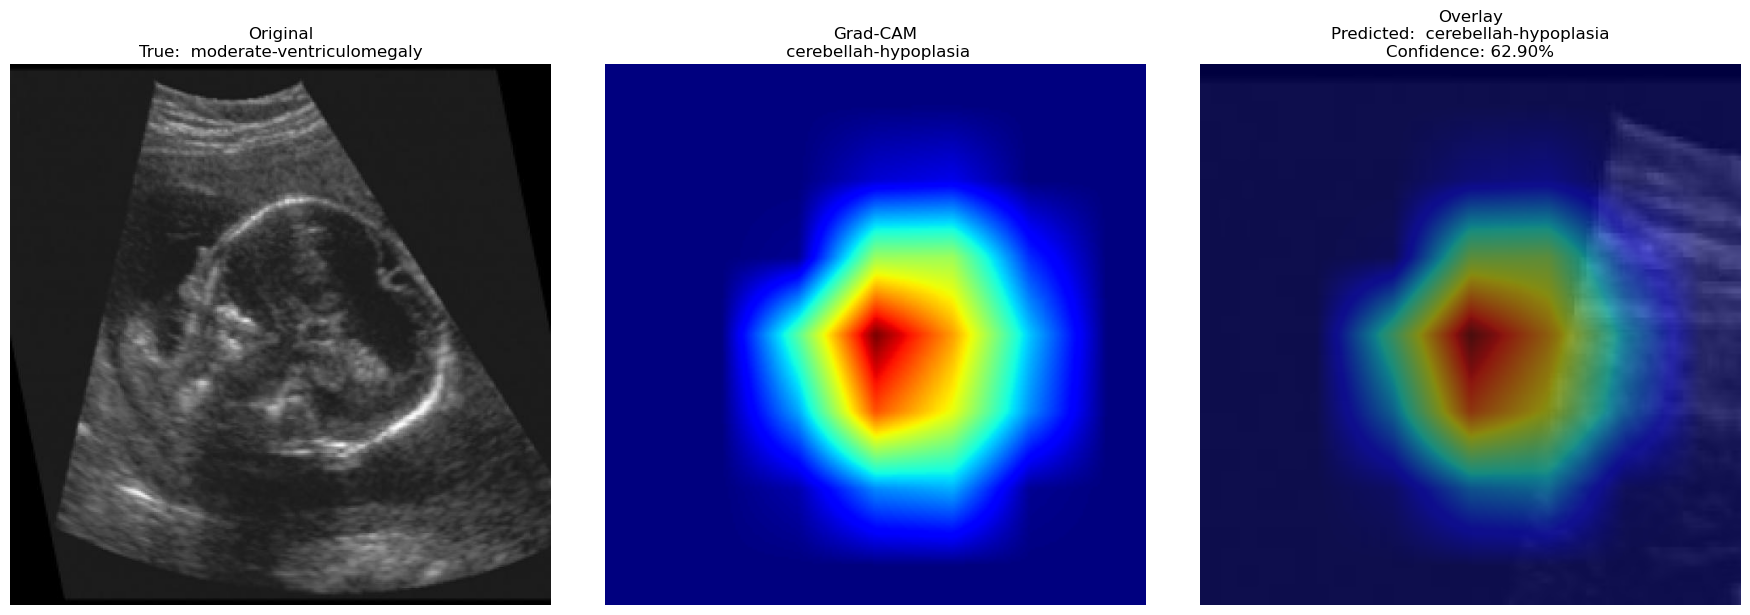

Filename: Copy-of-moderate-ventriculomegaly_20c_aug_3_png_jpg.rf.093372556bff5f67aa7c63cbec57ca9e.jpg
True class:  moderate-ventriculomegaly
Predicted class:  cerebellah-hypoplasia
Confidence: 62.90%


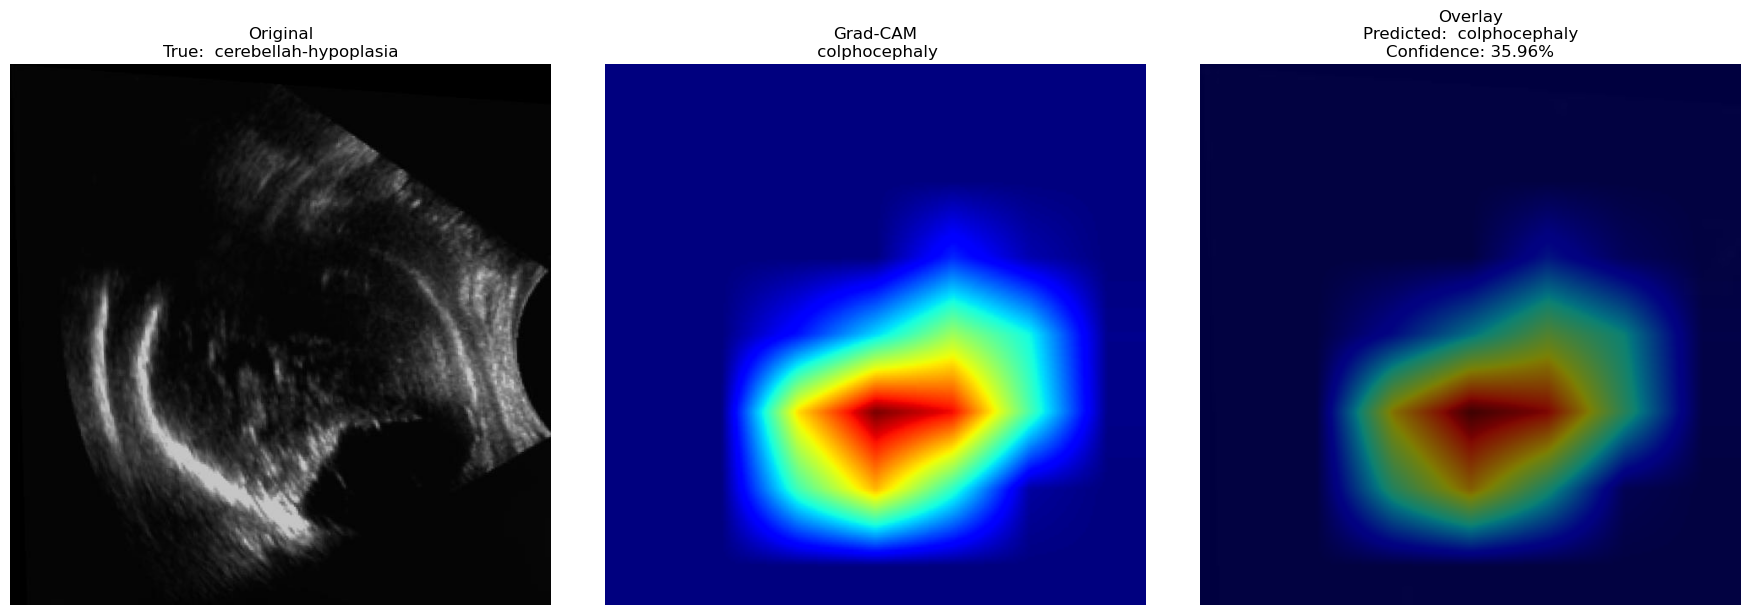

Filename: Copy-of-cerebellah-hypoplasia-36o_aug_5_png_jpg.rf.1651df9dd9ecc6c8b5377c505d18ab62.jpg
True class:  cerebellah-hypoplasia
Predicted class:  colphocephaly
Confidence: 35.96%


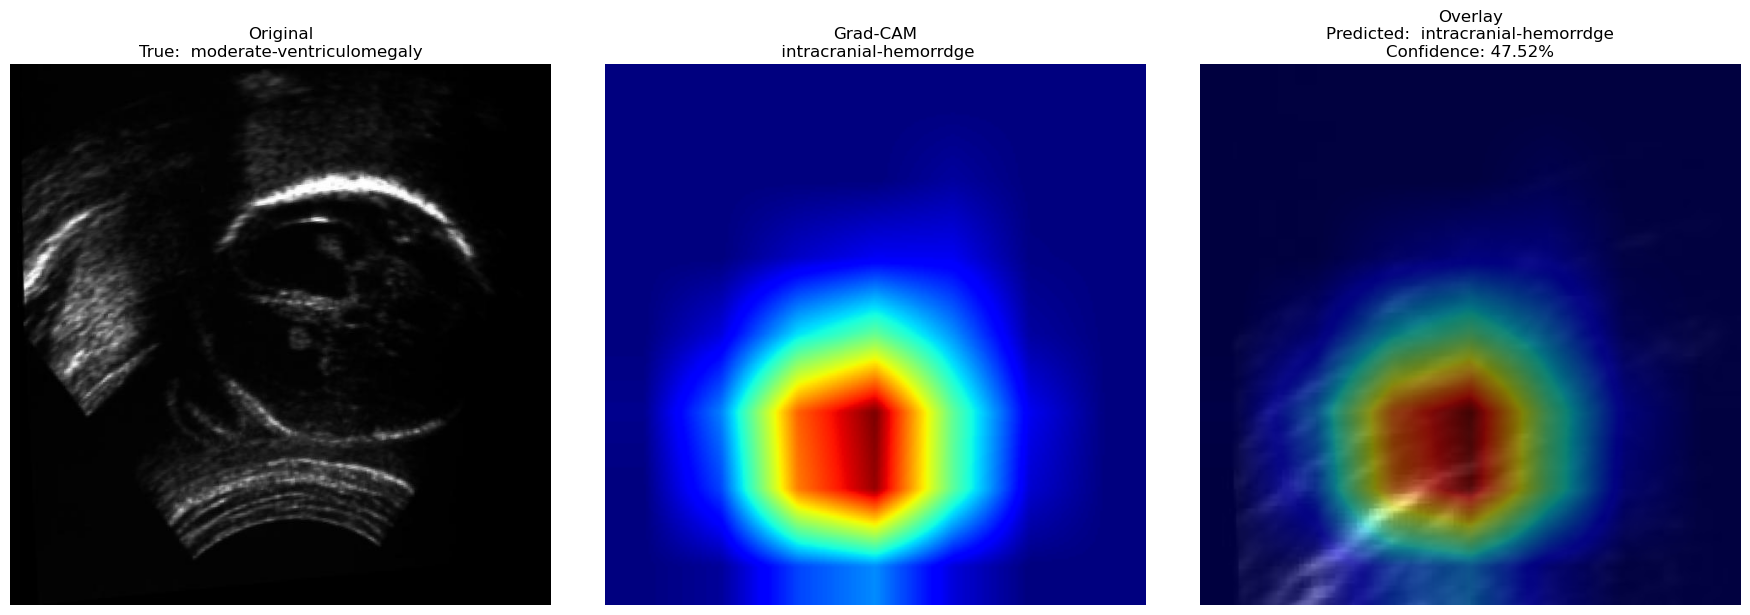

Filename: Copy-of-moderate-ventriculomegaly-26_aug_3_png_jpg.rf.18f8f1a5a31437eefd27bf993a6797b4.jpg
True class:  moderate-ventriculomegaly
Predicted class:  intracranial-hemorrdge
Confidence: 47.52%


In [32]:
num_samples = min(5, len(incorrect_indices))

for index in incorrect_indices[:num_samples]:

    show_gradcam(
        test_dataset,
        image_index=index,
        model=model,
        idx_to_class=idx_to_class
    )

In [33]:
def save_gradcam(
    dataset,
    image_index,
    model,
    idx_to_class,
    save_dir="gradcam_results"
):

    os.makedirs(save_dir, exist_ok=True)

    image_tensor, true_label, original_image, filename = dataset[image_index]

    input_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)

    probabilities = torch.softmax(output, dim=1)

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

    confidence = probabilities[
        0,
        predicted_class
    ].item()

    predicted_label = idx_to_class[predicted_class]

    cam, _ = generate_gradcam(
        model,
        input_tensor,
        predicted_class
    )

    plt.figure(figsize=(7, 7))

    plt.imshow(original_image)

    plt.imshow(
        cam,
        cmap="jet",
        alpha=0.5
    )

    plt.title(
        f"True: {true_label}\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )

    plt.axis("off")

    output_name = os.path.splitext(filename)[0]

    output_path = os.path.join(
        save_dir,
        f"{output_name}_gradcam.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print("Saved:", output_path)

In [34]:
save_gradcam(
    test_dataset,
    image_index=0,
    model=model,
    idx_to_class=idx_to_class
)

Saved: gradcam_results\Copy-of-mild-ventriculomegaly-18c_aug_2_png_jpg.rf.1a7978b80bec239d05c1870f509b7aaa_gradcam.png


In [35]:
os.makedirs("gradcam_results/correct", exist_ok=True)

for i, index in enumerate(correct_indices[:10]):

    image_tensor, true_label, original_image, filename = test_dataset[index]

    input_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)

    predicted_class = torch.argmax(
        output,
        dim=1
    ).item()

    predicted_label = idx_to_class[predicted_class]

    cam, _ = generate_gradcam(
        model,
        input_tensor,
        predicted_class
    )

    plt.figure(figsize=(7, 7))

    plt.imshow(original_image)

    plt.imshow(
        cam,
        cmap="jet",
        alpha=0.5
    )

    plt.title(
        f"True: {true_label}\n"
        f"Predicted: {predicted_label}"
    )

    plt.axis("off")

    plt.savefig(
        f"gradcam_results/correct/example_{i+1}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("Correct prediction Grad-CAM images saved.")

Correct prediction Grad-CAM images saved.


In [36]:
os.makedirs("gradcam_results/incorrect", exist_ok=True)

for i, index in enumerate(incorrect_indices[:10]):

    image_tensor, true_label, original_image, filename = test_dataset[index]

    input_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)

    predicted_class = torch.argmax(
        output,
        dim=1
    ).item()

    predicted_label = idx_to_class[predicted_class]

    cam, _ = generate_gradcam(
        model,
        input_tensor,
        predicted_class
    )

    plt.figure(figsize=(7, 7))

    plt.imshow(original_image)

    plt.imshow(
        cam,
        cmap="jet",
        alpha=0.5
    )

    plt.title(
        f"True: {true_label}\n"
        f"Predicted: {predicted_label}"
    )

    plt.axis("off")

    plt.savefig(
        f"gradcam_results/incorrect/example_{i+1}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("Incorrect prediction Grad-CAM images saved.")

Incorrect prediction Grad-CAM images saved.


In [37]:
forward_handle.remove()
backward_handle.remove()

print("Grad-CAM hooks removed.")

Grad-CAM hooks removed.


In [38]:
print("Notebook 5 completed successfully.")
print()
print("Model:", "ResNet50")
print("Target layer:", "layer4[-1].conv3")
print("Test images:", len(test_dataset))
print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))
print()
print("Grad-CAM results saved in:")
print("gradcam_results/")

Notebook 5 completed successfully.

Model: ResNet50
Target layer: layer4[-1].conv3
Test images: 176
Correct predictions: 146
Incorrect predictions: 30

Grad-CAM results saved in:
gradcam_results/
